But de ce Notebook est de Merge les fichiers de données avant le feature engenering et les modeles de prédiction

In [18]:
import pandas as pd
import numpy as np

In [19]:
#lecture du fichier effectif_metropole_2021_2024_respiratoire_exploitable.csv et affichage des informations sur le dataframe
df_effectif = pd.read_csv("../data/final_metropole/effectif_metropole_2021_2024_respiratoire_exploitable.csv")

df_effectif.info()

display(df_effectif.head(10))

df_effectif.shape

<class 'pandas.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 14 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   annee                                      384 non-null    int64  
 1   code_dept                                  384 non-null    str    
 2   Ntop_Maladie_Respi_Chronique_tsage_9       384 non-null    float64
 3   Npop_Maladie_Respi_Chronique_tsage_9       384 non-null    float64
 4   prev_Maladie_Respi_Chronique_tsage_9       384 non-null    float64
 5   Ntop_Maladie_Respi_Chronique_0-14_9        384 non-null    float64
 6   Ntop_Maladie_Respi_Chronique_15-64_9       384 non-null    float64
 7   Ntop_Maladie_Respi_Chronique_65+_9         384 non-null    float64
 8   Npop_Maladie_Respi_Chronique_0-14_9        384 non-null    float64
 9   Npop_Maladie_Respi_Chronique_15-64_9       384 non-null    float64
 10  Npop_Maladie_Respi_Chronique_65+_9   

,annee,code_dept,Ntop_Maladie_Respi_Chronique_tsage_9,Npop_Maladie_Respi_Chronique_tsage_9,prev_Maladie_Respi_Chronique_tsage_9,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
0,2021,01,29030.0,640570.0,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
1,2021,02,35010.0,525790.0,6.658,3570.0,16790.0,14650.0,91960.0,319770.0,114050.0,3.882123,5.250649,12.845243
2,2021,03,17930.0,333820.0,5.372,2080.0,7530.0,8330.0,47400.0,190880.0,95560.0,4.388186,3.944887,8.717036
3,2021,04,9450.0,169250.0,5.583,780.0,3950.0,4720.0,24390.0,99870.0,44990.0,3.198032,3.955142,10.491220
4,2021,05,6900.0,145180.0,4.750,640.0,2810.0,3450.0,21020.0,87130.0,37060.0,3.044719,3.225066,9.309228
5,2021,06,61090.0,1170100.0,5.221,7520.0,25060.0,28540.0,174560.0,711000.0,284540.0,4.307974,3.524613,10.030224
6,2021,07,16090.0,336430.0,4.781,1750.0,6840.0,7510.0,51190.0,199950.0,85310.0,3.418636,3.420855,8.803188
7,2021,08,19930.0,265250.0,7.512,2230.0,9460.0,8240.0,44000.0,160250.0,61010.0,5.068182,5.903276,13.505983
8,2021,09,9740.0,155300.0,6.273,1030.0,4020.0,4700.0,21690.0,91450.0,42180.0,4.748732,4.395845,11.142722
9,2021,10,14900.0,303390.0,4.912,1700.0,6850.0,6350.0,50550.0,182160.0,70690.0,3.363007,3.760430,8.982883


(384, 14)

In [20]:
#lecture du fichier final_meteo_hebdo_clean_96.csv et affichage des informations sur le dataframe
df_meteo = pd.read_csv("../data/final_metropole/final_meteo_hebdo_clean_96.csv")

df_meteo.info()

display(df_meteo.head(10))

df_meteo.shape

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 25 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   pression_mer                                19968 non-null  float64
 3   tendance_pression_3h                        19968 non-null  float64
 4   vent_direction                              19968 non-null  float64
 5   vent_vitesse                                19968 non-null  float64
 6   temperature_kelvin                          19968 non-null  float64
 7   humidite_relative                           19968 non-null  float64
 8   visibilite                                  19968 non-null  float64
 9   pression_station                            19968 non-null  float64
 10  periode_rafale       

,date_semaine,code_dept,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,humidite_relative,visibilite,pression_station,...,precipitation_24h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,2021-S01,01,101586.607143,13.928571,258.750000,1.875000,272.803571,87.767857,9165.000000,98595.535714,...,-3.4,0.0,0.0,6.0,0.0,3.0,1.0,46.0,0.0,0.0
1,2021-S01,02,101806.250000,19.464286,163.035714,2.142857,274.617857,88.946429,11832.142857,100615.357143,...,-3.1,0.0,2.0,4.0,0.0,0.0,4.0,46.0,0.0,0.0
2,2021-S01,03,101656.428571,16.250000,206.071429,1.339286,272.644643,82.392857,11617.857143,97613.035714,...,13.3,0.0,1.0,10.0,2.0,0.0,0.0,43.0,0.0,0.0
3,2021-S01,04,101740.000000,11.071429,106.071429,3.214286,271.585714,59.089286,18886.250000,90856.785714,...,5.5,0.0,0.0,0.0,3.0,0.0,0.0,53.0,0.0,0.0
4,2021-S01,05,101740.000000,11.071429,106.071429,3.214286,271.585714,59.089286,18886.250000,90856.785714,...,5.5,0.0,0.0,0.0,3.0,0.0,0.0,53.0,0.0,0.0
5,2021-S01,06,101048.571429,10.000000,280.892857,3.892857,279.242857,67.125000,41569.464286,100728.750000,...,69.8,1.0,0.0,1.0,0.0,5.0,0.0,49.0,0.0,0.0
6,2021-S01,07,101403.214286,12.500000,72.678571,4.660714,275.457143,72.107143,18030.714286,100479.285714,...,23.6,0.0,0.0,0.0,2.0,0.0,1.0,53.0,0.0,0.0
7,2021-S01,08,101806.250000,19.464286,163.035714,2.142857,274.617857,88.946429,11832.142857,100615.357143,...,-3.1,0.0,2.0,4.0,0.0,0.0,4.0,46.0,0.0,0.0
8,2021-S01,09,101551.428571,16.607143,70.535714,0.446429,272.439286,88.696429,12063.392857,96440.000000,...,130.6,0.0,1.0,3.0,11.0,0.0,0.0,41.0,0.0,0.0
9,2021-S01,10,101781.428571,19.107143,186.607143,1.571429,274.235714,88.607143,9799.464286,100302.500000,...,32.5,0.0,1.0,17.0,0.0,0.0,8.0,30.0,0.0,0.0


(19968, 25)

In [16]:
#lecture du fichier pollution_2021_2024.csv et affichage des informations sur le dataframe
df_pollution = pd.read_csv("../data/final_metropole/pollution_2021_2024.csv")

df_pollution.info()

display(df_pollution.head(10))

df_pollution.shape

display(df_pollution['date_semaine'].unique())

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date_semaine  19968 non-null  str    
 1   code_dept     19968 non-null  str    
 2   As in PM10    19968 non-null  float64
 3   BaP in PM10   19968 non-null  float64
 4   Cd in PM10    19968 non-null  float64
 5   Ni in PM10    19968 non-null  float64
 6   Pb in PM10    19968 non-null  float64
dtypes: float64(5), str(2)
memory usage: 1.1 MB


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10
0,2021-S01,01,0.326250,0.610000,0.050000,0.422500,0.002025
1,2021-S01,02,0.156000,0.725417,0.050000,0.503750,0.002756
2,2021-S01,03,0.224867,0.236667,0.063500,0.447000,0.002264
3,2021-S01,04,0.195000,0.521111,0.110417,0.421667,0.002683
4,2021-S01,05,0.293333,0.760000,0.045833,0.226667,0.001333
5,2021-S01,06,0.220000,0.520000,0.183333,0.703333,0.003767
6,2021-S01,07,0.242000,0.417778,0.045833,0.226667,0.002127
7,2021-S01,08,0.122500,0.120000,0.057500,0.250000,0.002250
8,2021-S01,09,0.214844,0.406250,0.205469,0.335781,0.002106
9,2021-S01,10,0.449296,2.203333,0.134759,0.757292,0.005021


<StringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S10',
 ...
 '2024-S43', '2024-S44', '2024-S45', '2024-S46', '2024-S47', '2024-S48',
 '2024-S49', '2024-S50', '2024-S51', '2024-S52']
Length: 208, dtype: str

In [17]:
#lecture du fichier sante_2021_2024_pathologies.csv et affichage des informations sur le dataframe
df_sante = pd.read_csv("../data/final_metropole/sante_2021_2024_pathologies.csv")

df_sante.info()

display(df_sante.head(10))

df_sante.shape

display(df_sante['date_semaine'].unique())

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 20 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   date_semaine                      19968 non-null  str    
 1   code_dept                         19968 non-null  str    
 2   TousAge_allergie_urgences         19968 non-null  float64
 3   65plus_allergie_urgences          19968 non-null  float64
 4   0_14_allergie_urgences            19968 non-null  float64
 5   15_64_allergie_urgences           19968 non-null  float64
 6   0_14_asthme_urgences              19968 non-null  float64
 7   15_64_asthme_urgences             19968 non-null  float64
 8   TousAge_asthme_urgences           19968 non-null  float64
 9   65plus_asthme_urgences            19968 non-null  float64
 10  0an_bronchiolite_urgences         19908 non-null  float64
 11  TousAge_allergie_hospitalisation  19892 non-null  float64
 12  65plus_allergie

,date_semaine,code_dept,TousAge_allergie_urgences,65plus_allergie_urgences,0_14_allergie_urgences,15_64_allergie_urgences,0_14_asthme_urgences,15_64_asthme_urgences,TousAge_asthme_urgences,65plus_asthme_urgences,0an_bronchiolite_urgences,TousAge_allergie_hospitalisation,65plus_allergie_hospitalisation,0_14_allergie_hospitalisation,15_64_allergie_hospitalisation,0_14_asthme_hospitalisation,15_64_asthme_hospitalisation,TousAge_asthme_hospitalisation,65plus_asthme_hospitalisation,0an_bronchiolite_hospitalisation
0,2021-S01,01,446.144041,481.927711,395.256917,443.951165,790.513834,554.938957,446.144041,0.000000,3846.153846,0.000000,0.000000,0.000000,0.000000,0.000000,943.396226,361.010830,0.000000,16666.666667
1,2021-S01,02,719.424460,280.112045,1464.435146,687.022901,418.410042,0.000000,79.936051,0.000000,4255.319149,581.395349,0.000000,2083.333333,1036.269430,0.000000,0.000000,0.000000,0.000000,0.000000
2,2021-S01,03,452.898551,232.558140,1562.500000,366.300366,781.250000,366.300366,362.318841,232.558140,0.000000,284.900285,408.163265,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
3,2021-S01,04,820.512821,336.700337,2222.222222,736.648250,0.000000,920.810313,615.384615,336.700337,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,2021-S01,05,618.811881,440.528634,0.000000,858.369099,0.000000,429.184549,247.524752,0.000000,0.000000,546.448087,0.000000,0.000000,1315.789474,0.000000,1315.789474,546.448087,0.000000,0.000000
5,2021-S01,06,816.961681,250.000000,1741.803279,818.713450,1536.885246,155.945419,408.480840,125.000000,5063.291139,485.773768,357.142857,943.396226,606.060606,6603.773585,0.000000,555.170021,119.047619,10714.285714
6,2021-S01,07,236.220472,0.000000,0.000000,409.836066,0.000000,136.612022,78.740157,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,2021-S01,08,175.284838,595.238095,0.000000,0.000000,0.000000,341.296928,262.927257,297.619048,3703.703704,0.000000,0.000000,0.000000,0.000000,0.000000,934.579439,699.300699,653.594771,0.000000
8,2021-S01,09,177.935943,497.512438,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,2021-S01,10,668.576886,346.020761,1948.051948,496.688742,1298.701299,165.562914,286.532951,0.000000,3846.153846,0.000000,0.000000,0.000000,0.000000,6896.551724,0.000000,772.200772,0.000000,10000.000000


<StringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S10',
 ...
 '2024-S43', '2024-S44', '2024-S45', '2024-S46', '2024-S47', '2024-S48',
 '2024-S49', '2024-S50', '2024-S51', '2024-S52']
Length: 208, dtype: str

In [21]:
# premier merge meteo + pollution => attendu 30 colonnes 19968 ligne
df_merge_1 = pd.merge(df_pollution, df_meteo, on=['code_dept', 'date_semaine'], how='outer')

assert len(df_merge_1) == len(df_meteo), f"Attention : Le nombre de lignes a changé ({len(df_merge_1)} vs {len(df_meteo)})"

df_merge_1.info()

display(df_merge_1.head(10))

df_merge_1.shape

display(df_merge_1['date_semaine'].unique())

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 30 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,precipitation_24h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,101586.607143,13.928571,258.750000,...,-3.4,0.0,0.0,6.0,0.0,3.0,1.0,46.0,0.0,0.0
1,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,102439.285714,14.285714,191.071429,...,347.9,1.0,0.0,4.0,6.0,5.0,16.0,24.0,0.0,0.0
2,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,101053.392857,-43.392857,170.178571,...,164.5,0.0,4.0,3.0,0.0,5.0,5.0,39.0,0.0,0.0
3,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,101230.000000,-12.500000,193.750000,...,190.3,0.0,3.0,1.0,0.0,9.0,9.0,34.0,0.0,0.0
4,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,100684.107143,6.250000,162.857143,...,211.2,0.0,0.0,0.0,0.0,5.0,15.0,36.0,0.0,0.0
5,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,101585.714286,59.464286,224.107143,...,73.1,0.0,0.0,3.0,3.0,2.0,6.0,42.0,0.0,0.0
6,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,102210.000000,-29.821429,159.285714,...,-0.9,0.0,2.0,0.0,0.0,0.0,1.0,53.0,0.0,0.0
7,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,102962.142857,21.428571,195.000000,...,0.5,0.0,0.0,0.0,0.0,0.0,1.0,55.0,0.0,0.0
8,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,102580.535714,-17.321429,196.607143,...,-1.2,0.0,0.0,1.0,0.0,1.0,1.0,53.0,0.0,0.0
9,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,101854.464286,6.250000,220.178571,...,113.2,1.0,0.0,1.0,0.0,3.0,3.0,48.0,0.0,0.0


<StringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S10',
 ...
 '2024-S43', '2024-S44', '2024-S45', '2024-S46', '2024-S47', '2024-S48',
 '2024-S49', '2024-S50', '2024-S51', '2024-S52']
Length: 208, dtype: str

In [22]:
# deuxieme merge merge 1 + sante => attendu 48 colonnes 19968 ligne
df_merge_2 = pd.merge(df_merge_1, df_sante, on=['code_dept', 'date_semaine'], how='outer')

assert len(df_merge_2) == len(df_merge_1), f"Attention : Le nombre de lignes a changé ({len(df_merge_1)} vs {len(df_meteo)})"

df_merge_2.info()

display(df_merge_2.head(10))

df_merge_2.shape

display(df_merge_2['date_semaine'].unique())

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 48 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,0an_bronchiolite_urgences,TousAge_allergie_hospitalisation,65plus_allergie_hospitalisation,0_14_allergie_hospitalisation,15_64_allergie_hospitalisation,0_14_asthme_hospitalisation,15_64_asthme_hospitalisation,TousAge_asthme_hospitalisation,65plus_asthme_hospitalisation,0an_bronchiolite_hospitalisation
0,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,101586.607143,13.928571,258.750000,...,3846.153846,0.000000,0.000000,0.0,0.000000,0.000000,943.396226,361.010830,0.000000,16666.666667
1,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,102439.285714,14.285714,191.071429,...,4761.904762,0.000000,0.000000,0.0,0.000000,0.000000,1030.927835,377.358491,0.000000,50000.000000
2,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,101053.392857,-43.392857,170.178571,...,0.000000,389.105058,0.000000,0.0,980.392157,8108.108108,980.392157,1556.420233,0.000000,0.000000
3,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,101230.000000,-12.500000,193.750000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,100684.107143,6.250000,162.857143,...,7692.307692,0.000000,0.000000,0.0,0.000000,3225.806452,0.000000,389.105058,0.000000,28571.428571
5,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,101585.714286,59.464286,224.107143,...,7407.407407,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,335.570470,621.118012,14285.714286
6,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,102210.000000,-29.821429,159.285714,...,10810.810811,0.000000,0.000000,0.0,0.000000,0.000000,1724.137931,1010.101010,636.942675,0.000000
7,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,102962.142857,21.428571,195.000000,...,12000.000000,370.370370,0.000000,0.0,980.392157,0.000000,0.000000,0.000000,0.000000,33333.333333
8,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,102580.535714,-17.321429,196.607143,...,8000.000000,0.000000,0.000000,0.0,0.000000,0.000000,854.700855,677.966102,671.140940,33333.333333
9,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,101854.464286,6.250000,220.178571,...,3448.275862,664.451827,1307.189543,0.0,0.000000,4545.454545,0.000000,332.225914,0.000000,0.000000


<StringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S10',
 ...
 '2024-S43', '2024-S44', '2024-S45', '2024-S46', '2024-S47', '2024-S48',
 '2024-S49', '2024-S50', '2024-S51', '2024-S52']
Length: 208, dtype: str

In [25]:
#1. Extraire l'année de la colonne date_semaine (ex: '2021-S01' -> '2021')
df_merge_2['annee'] = df_merge_2['date_semaine'].str[:4]

# Réordonner les colonnes pour mettre 'annee' en première position
cols = ['annee'] + [col for col in df_merge_2.columns if col != 'annee']
df_merge_2 = df_merge_2[cols]

# Assure-toi que le format de l'année est le même dans les deux DataFrames (ex: type string ou int)
df_effectif['annee'] = df_effectif['annee'].astype(str)

display(df_merge_2.info())
display(df_merge_2.head(10))

display(df_effectif.info())
display(df_effectif.head(10))


<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 49 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   annee                                       19968 non-null  str    
 1   date_semaine                                19968 non-null  str    
 2   code_dept                                   19968 non-null  str    
 3   As in PM10                                  19968 non-null  float64
 4   BaP in PM10                                 19968 non-null  float64
 5   Cd in PM10                                  19968 non-null  float64
 6   Ni in PM10                                  19968 non-null  float64
 7   Pb in PM10                                  19968 non-null  float64
 8   pression_mer                                19968 non-null  float64
 9   tendance_pression_3h                        19968 non-null  float64
 10  vent_direction       

None

,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,...,0an_bronchiolite_urgences,TousAge_allergie_hospitalisation,65plus_allergie_hospitalisation,0_14_allergie_hospitalisation,15_64_allergie_hospitalisation,0_14_asthme_hospitalisation,15_64_asthme_hospitalisation,TousAge_asthme_hospitalisation,65plus_asthme_hospitalisation,0an_bronchiolite_hospitalisation
0,2021,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,101586.607143,13.928571,...,3846.153846,0.000000,0.000000,0.0,0.000000,0.000000,943.396226,361.010830,0.000000,16666.666667
1,2021,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,102439.285714,14.285714,...,4761.904762,0.000000,0.000000,0.0,0.000000,0.000000,1030.927835,377.358491,0.000000,50000.000000
2,2021,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,101053.392857,-43.392857,...,0.000000,389.105058,0.000000,0.0,980.392157,8108.108108,980.392157,1556.420233,0.000000,0.000000
3,2021,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,101230.000000,-12.500000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,2021,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,100684.107143,6.250000,...,7692.307692,0.000000,0.000000,0.0,0.000000,3225.806452,0.000000,389.105058,0.000000,28571.428571
5,2021,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,101585.714286,59.464286,...,7407.407407,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,335.570470,621.118012,14285.714286
6,2021,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,102210.000000,-29.821429,...,10810.810811,0.000000,0.000000,0.0,0.000000,0.000000,1724.137931,1010.101010,636.942675,0.000000
7,2021,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,102962.142857,21.428571,...,12000.000000,370.370370,0.000000,0.0,980.392157,0.000000,0.000000,0.000000,0.000000,33333.333333
8,2021,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,102580.535714,-17.321429,...,8000.000000,0.000000,0.000000,0.0,0.000000,0.000000,854.700855,677.966102,671.140940,33333.333333
9,2021,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,101854.464286,6.250000,...,3448.275862,664.451827,1307.189543,0.0,0.000000,4545.454545,0.000000,332.225914,0.000000,0.000000


<class 'pandas.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 14 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   annee                                      384 non-null    str    
 1   code_dept                                  384 non-null    str    
 2   Ntop_Maladie_Respi_Chronique_tsage_9       384 non-null    float64
 3   Npop_Maladie_Respi_Chronique_tsage_9       384 non-null    float64
 4   prev_Maladie_Respi_Chronique_tsage_9       384 non-null    float64
 5   Ntop_Maladie_Respi_Chronique_0-14_9        384 non-null    float64
 6   Ntop_Maladie_Respi_Chronique_15-64_9       384 non-null    float64
 7   Ntop_Maladie_Respi_Chronique_65+_9         384 non-null    float64
 8   Npop_Maladie_Respi_Chronique_0-14_9        384 non-null    float64
 9   Npop_Maladie_Respi_Chronique_15-64_9       384 non-null    float64
 10  Npop_Maladie_Respi_Chronique_65+_9   

None

,annee,code_dept,Ntop_Maladie_Respi_Chronique_tsage_9,Npop_Maladie_Respi_Chronique_tsage_9,prev_Maladie_Respi_Chronique_tsage_9,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
0,2021,01,29030.0,640570.0,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
1,2021,02,35010.0,525790.0,6.658,3570.0,16790.0,14650.0,91960.0,319770.0,114050.0,3.882123,5.250649,12.845243
2,2021,03,17930.0,333820.0,5.372,2080.0,7530.0,8330.0,47400.0,190880.0,95560.0,4.388186,3.944887,8.717036
3,2021,04,9450.0,169250.0,5.583,780.0,3950.0,4720.0,24390.0,99870.0,44990.0,3.198032,3.955142,10.491220
4,2021,05,6900.0,145180.0,4.750,640.0,2810.0,3450.0,21020.0,87130.0,37060.0,3.044719,3.225066,9.309228
5,2021,06,61090.0,1170100.0,5.221,7520.0,25060.0,28540.0,174560.0,711000.0,284540.0,4.307974,3.524613,10.030224
6,2021,07,16090.0,336430.0,4.781,1750.0,6840.0,7510.0,51190.0,199950.0,85310.0,3.418636,3.420855,8.803188
7,2021,08,19930.0,265250.0,7.512,2230.0,9460.0,8240.0,44000.0,160250.0,61010.0,5.068182,5.903276,13.505983
8,2021,09,9740.0,155300.0,6.273,1030.0,4020.0,4700.0,21690.0,91450.0,42180.0,4.748732,4.395845,11.142722
9,2021,10,14900.0,303390.0,4.912,1700.0,6850.0,6350.0,50550.0,182160.0,70690.0,3.363007,3.760430,8.982883


In [27]:
# troisieme merge merge 2 + effectif => attendu 61 colonnes 19968 ligne
df_merge_3 = pd.merge(
    df_merge_2, 
    df_effectif, 
    on=['code_dept', 'annee'], 
    how='left'
)

df_merge_3.info()

display(df_merge_3.head(10))

display(df_merge_3.tail(10))
df_merge_3.shape



<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 61 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   annee                                       19968 non-null  str    
 1   date_semaine                                19968 non-null  str    
 2   code_dept                                   19968 non-null  str    
 3   As in PM10                                  19968 non-null  float64
 4   BaP in PM10                                 19968 non-null  float64
 5   Cd in PM10                                  19968 non-null  float64
 6   Ni in PM10                                  19968 non-null  float64
 7   Pb in PM10                                  19968 non-null  float64
 8   pression_mer                                19968 non-null  float64
 9   tendance_pression_3h                        19968 non-null  float64
 10  vent_direction       

,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,...,prev_Maladie_Respi_Chronique_tsage_9,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
0,2021,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,101586.607143,13.928571,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
1,2021,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,102439.285714,14.285714,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
2,2021,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,101053.392857,-43.392857,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
3,2021,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,101230.000000,-12.500000,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
4,2021,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,100684.107143,6.250000,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
5,2021,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,101585.714286,59.464286,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
6,2021,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,102210.000000,-29.821429,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
7,2021,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,102962.142857,21.428571,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
8,2021,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,102580.535714,-17.321429,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162
9,2021,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,101854.464286,6.250000,...,4.532,4330.0,12970.0,11740.0,119000.0,399590.0,122010.0,3.638655,3.245827,9.622162


,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,...,prev_Maladie_Respi_Chronique_tsage_9,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
19958,2024,2024-S43,95,0.232500,0.13750,0.042500,0.607500,0.002172,102132.500000,15.357143,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413
19959,2024,2024-S44,95,0.270833,0.15875,0.050000,0.640000,0.002514,102568.035714,-4.285714,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413
19960,2024,2024-S45,95,0.315417,0.14500,0.061250,0.716250,0.002715,102449.107143,13.214286,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413
19961,2024,2024-S46,95,0.291250,0.26500,0.060000,0.725000,0.002511,102874.642857,-21.964286,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413
19962,2024,2024-S47,95,0.221250,0.35000,0.067500,0.687500,0.003386,100652.857143,-38.214286,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413
19963,2024,2024-S48,95,0.203750,0.14000,0.062083,0.631667,0.003493,101712.500000,32.678571,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413
19964,2024,2024-S49,95,0.192500,0.64500,0.062917,0.619583,0.003966,101943.392857,13.750000,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413
19965,2024,2024-S50,95,0.180000,0.20250,0.060000,0.587500,0.004320,102800.714286,22.321429,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413
19966,2024,2024-S51,95,0.170000,0.13500,0.053333,0.530000,0.003680,102130.178571,-22.321429,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413
19967,2024,2024-S52,95,0.180000,0.77000,0.059167,0.498750,0.003381,103126.071429,14.821429,...,5.739,15910.0,35790.0,22820.0,269710.0,832930.0,195420.0,5.898928,4.29688,11.677413


(19968, 61)

In [28]:
df_socio = pd.read_csv("../data/processed/socio_eco_dep_modele.csv")

df_socio.info()

display(df_socio.head(10))

df_socio.shape

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   code_dept              96 non-null     str    
 1   nom_dep                96 non-null     str    
 2   pct_urbain             96 non-null     float64
 3   pct_artisans           96 non-null     float64
 4   pct_cadres             96 non-null     float64
 5   pct_prof_inter         96 non-null     float64
 6   pct_employes           96 non-null     float64
 7   pct_ouvriers           96 non-null     float64
 8   pct_retraites          96 non-null     float64
 9   pct_sans_activite      96 non-null     float64
 10  pct_agriculteurs       96 non-null     float64
 11  densite_generalistes   96 non-null     float64
 12  densite_pediatres      96 non-null     float64
 13  densite_pneumologues   96 non-null     float64
 14  densite_allergologues  96 non-null     float64
 15  densite_kines      

,code_dept,nom_dep,pct_urbain,pct_artisans,pct_cadres,pct_prof_inter,pct_employes,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,01,Ain,67.0,4.1,10.0,16.6,15.5,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,02,Aisne,53.2,2.7,4.8,12.4,16.0,16.5,30.0,16.6,1.0,59.944065,9.927529,3.083939,0.770985,56.667380,True
2,03,Allier,58.3,3.3,4.9,11.3,15.2,13.0,37.6,13.2,1.6,66.446381,10.485258,1.503312,0.300662,105.532488,False
3,04,Alpes-Hte-Provence,61.9,5.4,6.6,13.3,14.4,10.5,34.9,13.5,1.5,89.513916,39.306631,0.588907,0.588907,141.926669,True
4,05,Hautes-Alpes,59.5,5.4,5.9,15.2,16.2,9.9,34.6,11.2,1.6,125.346816,0.000000,0.000000,0.000000,269.706914,False
5,06,Alpes-Maritimes,95.9,5.2,10.5,13.5,16.5,8.4,30.2,15.6,0.1,101.685915,47.831156,3.982477,0.707996,167.441037,False
6,07,Ardèche,63.3,4.6,5.9,13.6,14.6,12.7,34.9,12.2,1.4,66.182515,9.408931,2.374261,0.593565,110.106337,False
7,08,Ardennes,57.3,3.1,4.5,12.6,15.6,16.1,31.0,15.9,1.2,72.949991,11.483166,0.759896,0.759896,105.625508,False
8,09,Ariège,55.5,4.6,5.4,12.5,16.2,11.0,35.2,13.3,1.8,82.277230,22.069209,2.551232,0.000000,157.538571,False
9,10,Aube,61.3,3.0,6.1,12.7,15.7,14.6,30.9,15.6,1.5,59.820538,9.499924,0.321616,0.643232,77.831023,True


(96, 17)

In [29]:
# Merge final merge 3 + socio eco => attendu 77 colonnes 19968 ligne
Merge_final = pd.merge(
    df_merge_3, 
    df_socio, 
    on='code_dept', 
    how='left'
)


Merge_final.info()

display(Merge_final.head(10))

display(Merge_final.tail(10))

Merge_final.shape

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 77 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   annee                                       19968 non-null  str    
 1   date_semaine                                19968 non-null  str    
 2   code_dept                                   19968 non-null  str    
 3   As in PM10                                  19968 non-null  float64
 4   BaP in PM10                                 19968 non-null  float64
 5   Cd in PM10                                  19968 non-null  float64
 6   Ni in PM10                                  19968 non-null  float64
 7   Pb in PM10                                  19968 non-null  float64
 8   pression_mer                                19968 non-null  float64
 9   tendance_pression_3h                        19968 non-null  float64
 10  vent_direction       

,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,101586.607143,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,102439.285714,14.285714,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,101053.392857,-43.392857,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,101230.000000,-12.500000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,100684.107143,6.250000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
5,2021,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,101585.714286,59.464286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
6,2021,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,102210.000000,-29.821429,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
7,2021,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,102962.142857,21.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
8,2021,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,102580.535714,-17.321429,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
9,2021,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,101854.464286,6.250000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
19958,2024,2024-S43,95,0.232500,0.13750,0.042500,0.607500,0.002172,102132.500000,15.357143,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19959,2024,2024-S44,95,0.270833,0.15875,0.050000,0.640000,0.002514,102568.035714,-4.285714,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19960,2024,2024-S45,95,0.315417,0.14500,0.061250,0.716250,0.002715,102449.107143,13.214286,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19961,2024,2024-S46,95,0.291250,0.26500,0.060000,0.725000,0.002511,102874.642857,-21.964286,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19962,2024,2024-S47,95,0.221250,0.35000,0.067500,0.687500,0.003386,100652.857143,-38.214286,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19963,2024,2024-S48,95,0.203750,0.14000,0.062083,0.631667,0.003493,101712.500000,32.678571,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19964,2024,2024-S49,95,0.192500,0.64500,0.062917,0.619583,0.003966,101943.392857,13.750000,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19965,2024,2024-S50,95,0.180000,0.20250,0.060000,0.587500,0.004320,102800.714286,22.321429,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19966,2024,2024-S51,95,0.170000,0.13500,0.053333,0.530000,0.003680,102130.178571,-22.321429,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19967,2024,2024-S52,95,0.180000,0.77000,0.059167,0.498750,0.003381,103126.071429,14.821429,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True


(19968, 77)

In [30]:
Merge_final = Merge_final.drop(columns=['annee'], errors='ignore')

Merge_final.info()

display(Merge_final.head())

display(Merge_final.tail())

Merge_final.shape

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 76 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,101586.607143,13.928571,258.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,102439.285714,14.285714,191.071429,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,101053.392857,-43.392857,170.178571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,101230.000000,-12.500000,193.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,100684.107143,6.250000,162.857143,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
19963,2024-S48,95,0.20375,0.1400,0.062083,0.631667,0.003493,101712.500000,32.678571,170.714286,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19964,2024-S49,95,0.19250,0.6450,0.062917,0.619583,0.003966,101943.392857,13.750000,244.642857,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19965,2024-S50,95,0.18000,0.2025,0.060000,0.587500,0.004320,102800.714286,22.321429,130.714286,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19966,2024-S51,95,0.17000,0.1350,0.053333,0.530000,0.003680,102130.178571,-22.321429,231.250000,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19967,2024-S52,95,0.18000,0.7700,0.059167,0.498750,0.003381,103126.071429,14.821429,198.392857,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True


(19968, 76)

In [31]:
Merge_final.to_csv("../data/final_metropole/Merge_final.csv", index=False, encoding='utf-8')

In [32]:
Merge_final = pd.read_csv("../data/final_metropole/Merge_final.csv")

Merge_final.info()

Merge_final.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 76 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

C:\Users\gauxm\AppData\Local\Temp\ipykernel_24624\3244748483.py:1: DtypeWarning: Columns (1: code_dept) have mixed types. Specify dtype option on import or set low_memory=False.
  Merge_final = pd.read_csv("../data/final_metropole/Merge_final.csv")


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,101586.607143,13.928571,258.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,102439.285714,14.285714,191.071429,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,101053.392857,-43.392857,170.178571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,101230.000000,-12.500000,193.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,100684.107143,6.250000,162.857143,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


In [34]:
#NA
valeurs_manquantes = Merge_final.isnull().sum()
print(valeurs_manquantes[valeurs_manquantes > 0])

# Vérification du nombre de départements et de semaines
print(f"\nNombre de départements uniques : {Merge_final['code_dept'].unique()}")
print(f"Nombre de semaines uniques     : {Merge_final['date_semaine'].unique()}")

0an_bronchiolite_urgences             60
TousAge_allergie_hospitalisation      76
65plus_allergie_hospitalisation      106
0_14_allergie_hospitalisation        254
15_64_allergie_hospitalisation       118
0_14_asthme_hospitalisation          254
15_64_asthme_hospitalisation         118
TousAge_asthme_hospitalisation        76
65plus_asthme_hospitalisation        106
0an_bronchiolite_hospitalisation    1335
dtype: int64

Nombre de départements uniques : ['01' '02' '03' '04' '05' '06' '07' '08' '09' '10' '11' '12' '13' '14'
 '15' '16' '17' '18' '19' '21' '22' '23' '24' '25' '26' '27' '28' '29'
 '2A' '2B' '30' '31' '32' '33' '34' '35' '36' '37' '38' '39' 39 40 41 42
 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66
 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90
 91 92 93 94 95]
Nombre de semaines uniques     : <StringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S1

In [35]:
Merge_final.describe()

,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,...,pct_employes,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines
count,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,...,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000
mean,0.261245,0.151671,0.057315,0.919203,0.002397,101731.132958,4.767559,186.423679,3.177440,286.248787,...,15.204167,12.438542,31.028125,14.405208,1.122917,73.910446,19.467049,1.649773,0.489102,113.342456
std,0.158136,0.293028,0.038881,2.100384,0.001894,637.609307,26.564899,47.250325,1.300443,6.412574,...,1.105875,2.491647,5.302367,2.457210,0.892056,16.386317,12.840241,0.849758,0.395713,45.027645
min,0.010000,0.000000,0.000000,0.010000,0.000000,98727.500000,-109.473684,23.392857,0.446429,268.201786,...,11.200000,4.000000,16.400000,9.900000,0.000000,44.103662,0.000000,0.000000,0.000000,47.316511
25%,0.163333,0.015000,0.033174,0.367500,0.001300,101394.642857,-9.642857,157.857143,2.267857,281.373214,...,14.600000,10.800000,28.025000,12.400000,0.500000,59.315987,10.540324,0.985602,0.262798,77.723393
50%,0.230000,0.042500,0.050000,0.547500,0.001956,101729.375000,1.250000,193.512987,2.928571,285.844643,...,15.100000,12.550000,31.100000,14.100000,1.000000,74.610765,17.485046,1.590019,0.420624,101.898786
75%,0.313535,0.170000,0.070000,0.825000,0.003036,102040.000000,12.500000,218.750000,3.839286,291.287946,...,15.700000,14.200000,35.125000,16.000000,1.500000,86.650638,24.372302,2.122395,0.619918,137.225844
max,3.530000,9.755000,1.350000,134.720000,0.052800,103774.259259,156.607143,331.785714,12.600000,302.580357,...,19.100000,17.400000,41.100000,23.300000,4.700000,125.346816,87.236090,4.344889,2.167333,269.706914


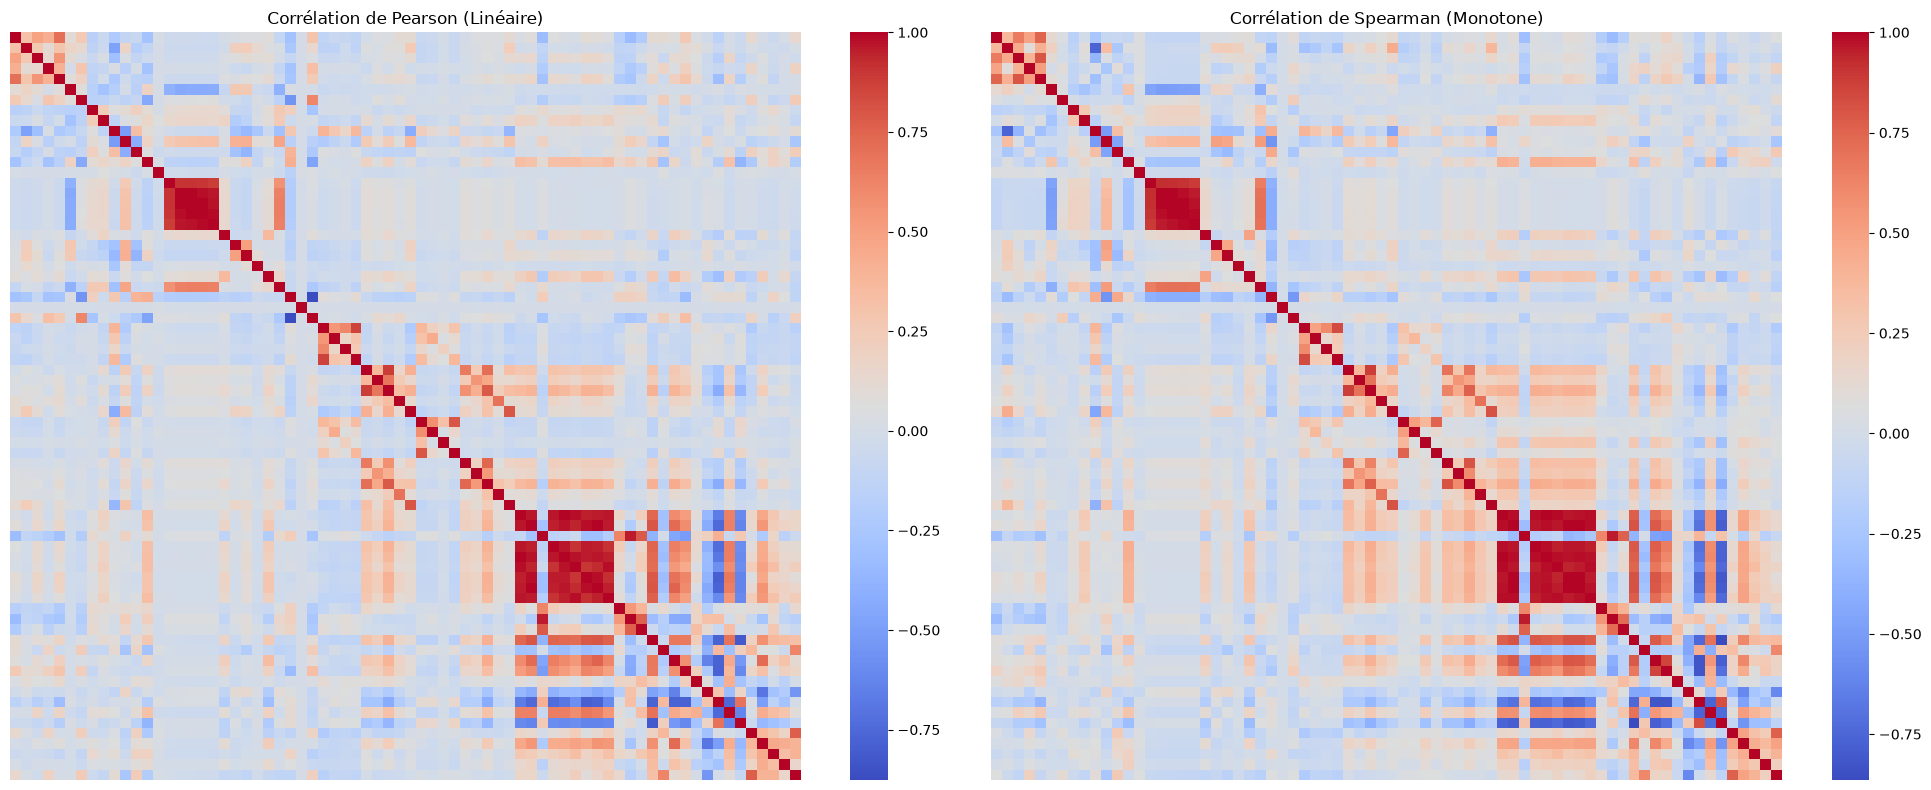

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sélection des variables numériques
numeric_cols = Merge_final.select_dtypes(include=['float64', 'int64']).columns

# 1. Calcul des deux matrices
corr_pearson = Merge_final[numeric_cols].corr(method='pearson')
corr_spearman = Merge_final[numeric_cols].corr(method='spearman')

# 2. Affichage côte à côte
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Heatmap Pearson
sns.heatmap(corr_pearson, annot=False, cmap='coolwarm', ax=axes[0])
axes[0].set_title('Corrélation de Pearson (Linéaire)')

axes[0].set_xticks([])
axes[0].set_yticks([])

# Heatmap Spearman
sns.heatmap(corr_spearman, annot=False, cmap='coolwarm', ax=axes[1])
axes[1].set_title('Corrélation de Spearman (Monotone)')

axes[1].set_xticks([])
axes[1].set_yticks([])


plt.tight_layout()
plt.show()